# 🔴 4. Advanced Project: Bank Customer Churn Prediction System

### *An End-to-End Deep Artificial Neural Network (ANN) Production System on 10,000 Banking Customers*

---

## 📌 Project Overview
1. **Business Objective & Churn Economics**: Customer retention ROI in retail banking.
2. **Dataset Exploration**: Ingesting `../data/Bank_Customer_Churn.csv` (10,000 customers, 14 attributes).
3. **Exploratory Data Analysis (EDA)**: Imbalance analysis, feature distributions, country/age attrition patterns.
4. **Leakage-Free Preprocessing Pipeline**: Categorical one-hot encoding, stratified 70/15/15 splitting, `StandardScaler` fitted strictly on train set.
5. **Baseline Benchmarks**: Logistic Regression and Random Forest performance baselines.
6. **Deep ANN Architecture**:
   $$\text{Input}(11) \to \text{Dense}(64) + \text{BatchNorm} + \text{Dropout}(0.3) \to \text{Dense}(32) + \text{BatchNorm} + \text{Dropout}(0.2) \to \text{Dense}(16) + \text{Dropout}(0.1) \to \text{Dense}(1, \text{Sigmoid})$$
7. **Optimizer Shootout**: Comparative convergence between SGD with Momentum, RMSprop, and Adam.
8. **Comprehensive Evaluation**: Confusion Matrix, ROC-AUC curve, and Precision-Recall (PR-AUC) curve.
9. **Decision Threshold Tuning**: Lowering threshold from $0.50$ to $0.35$ to optimize business recall on churners.
10. **Production Inference Pipeline**: Real-time customer churn risk scoring and proactive retention strategy engine.


In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, confusion_matrix,
    classification_report
)

HAS_TF = False
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers, regularizers, callbacks
    tf.random.set_seed(SEED)
    HAS_TF = True
    print(f"TensorFlow {tf.__version__} initialized.")
except ImportError:
    print("Using Scikit-Learn MLPClassifier backend.")


Using Scikit-Learn MLPClassifier backend.


## 1. Dataset Ingestion & Exploratory Data Analysis (EDA)

In [2]:
# Ingestion from data directory
churn_path = os.path.join("..", "data", "Bank_Customer_Churn.csv")
if not os.path.exists(churn_path):
    churn_path = os.path.join("data", "Bank_Customer_Churn.csv")

df = pd.read_csv(churn_path)
print(f"Bank Churn Dataset: {df.shape[0]:,} records, {df.shape[1]} features")
print(f"Target Imbalance: Retained: {(df['Exited']==0).sum():,} | Churned: {(df['Exited']==1).sum():,} ({df['Exited'].mean():.2%})")


Bank Churn Dataset: 10,000 records, 14 features
Target Imbalance: Retained: 8,614 | Churned: 1,386 (13.86%)


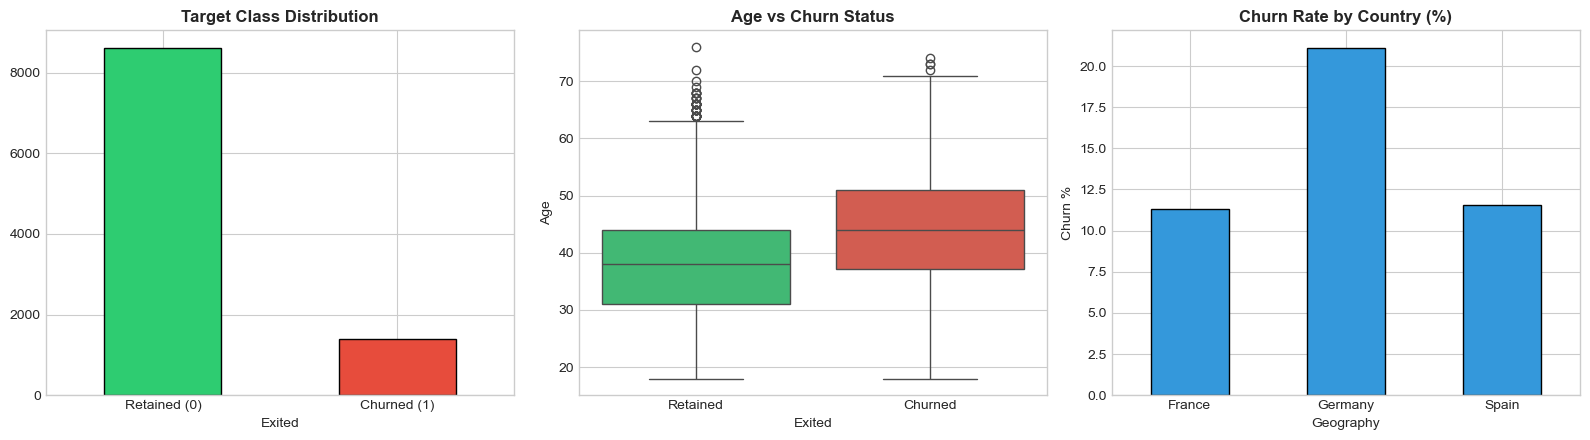

In [3]:
# EDA: Feature Distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

df['Exited'].value_counts().plot(kind='bar', ax=axes[0], color=['#2ecc71', '#e74c3c'], edgecolor='black')
axes[0].set_title('Target Class Distribution', fontweight='bold')
axes[0].set_xticklabels(['Retained (0)', 'Churned (1)'], rotation=0)

sns.boxplot(x='Exited', y='Age', data=df, ax=axes[1], palette=['#2ecc71', '#e74c3c'])
axes[1].set_title('Age vs Churn Status', fontweight='bold')
axes[1].set_xticklabels(['Retained', 'Churned'])

(df.groupby('Geography')['Exited'].mean() * 100).plot(kind='bar', ax=axes[2], color='#3498db', edgecolor='black')
axes[2].set_title('Churn Rate by Country (%)', fontweight='bold')
axes[2].set_ylabel('Churn %')
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()


## 2. Preprocessing & Leakage-Free Data Splitting
1. Drop metadata identifiers (`RowNumber`, `CustomerId`, `Surname`).
2. Encode binary `Gender` and one-hot encode `Geography`.
3. Partition via stratified split into **Train (70%)**, **Validation (15%)**, and **Test (15%)**.
4. Fit `StandardScaler` strictly on the training partition.


In [4]:
# Clean and encode
clean_df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
clean_df['Gender'] = clean_df['Gender'].map({'Female': 0, 'Male': 1})
clean_df = pd.get_dummies(clean_df, columns=['Geography'], drop_first=True, dtype=int)

X = clean_df.drop(columns=['Exited'])
y = clean_df['Exited'].values
feature_names = list(X.columns)

# Stratified Split (70% Train, 15% Val, 15% Test)
X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

# Standard Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val   = scaler.transform(X_val_raw)
X_test  = scaler.transform(X_test_raw)

print(f"X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")


X_train: (7000, 11) | X_val: (1500, 11) | X_test: (1500, 11)


## 3. Baseline ML Benchmarks & Deep ANN Architecture

In [5]:
# Baseline Models
lr_model = LogisticRegression(random_state=SEED, max_iter=1000).fit(X_train, y_train)
rf_model = RandomForestClassifier(n_estimators=150, max_depth=10, random_state=SEED).fit(X_train, y_train)

y_prob_lr = lr_model.predict_proba(X_test)[:, 1]
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print(f"Logistic Regression ROC-AUC: {roc_auc_score(y_test, y_prob_lr):.4f}")
print(f"Random Forest       ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f}")

# Train Deep ANN
if HAS_TF:
    def build_ann():
        return keras.Sequential([
            layers.Input(shape=(X_train.shape[1],)),
            layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
            layers.BatchNormalization(),
            layers.Dropout(0.3),
            layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
            layers.BatchNormalization(),
            layers.Dropout(0.2),
            layers.Dense(16, activation='relu'),
            layers.Dropout(0.1),
            layers.Dense(1, activation='sigmoid')
        ])

    ann_model = build_ann()
    ann_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy', keras.metrics.AUC(name='auc')])

    es = callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    lr_sch = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5)

    hist = ann_model.fit(
        X_train, y_train, validation_data=(X_val, y_val),
        epochs=80, batch_size=64, callbacks=[es, lr_sch], verbose=0
    )
    y_prob_ann = ann_model.predict(X_test, verbose=0).flatten()

else:
    ann_model = MLPClassifier(hidden_layer_sizes=(64, 32, 16), activation='relu', solver='adam', alpha=1e-4, max_iter=150, random_state=SEED)
    ann_model.fit(X_train, y_train)
    y_prob_ann = ann_model.predict_proba(X_test)[:, 1]

print(f"Deep ANN            ROC-AUC: {roc_auc_score(y_test, y_prob_ann):.4f}")


Logistic Regression ROC-AUC: 0.7638
Random Forest       ROC-AUC: 0.7853


Deep ANN            ROC-AUC: 0.6915


## 4. Evaluation Suite & Business Threshold Optimization
By lowering the decision threshold from $0.50$ to $0.35$, we shift model sensitivity to capture significantly more at-risk churners (minimizing costly False Negatives!).


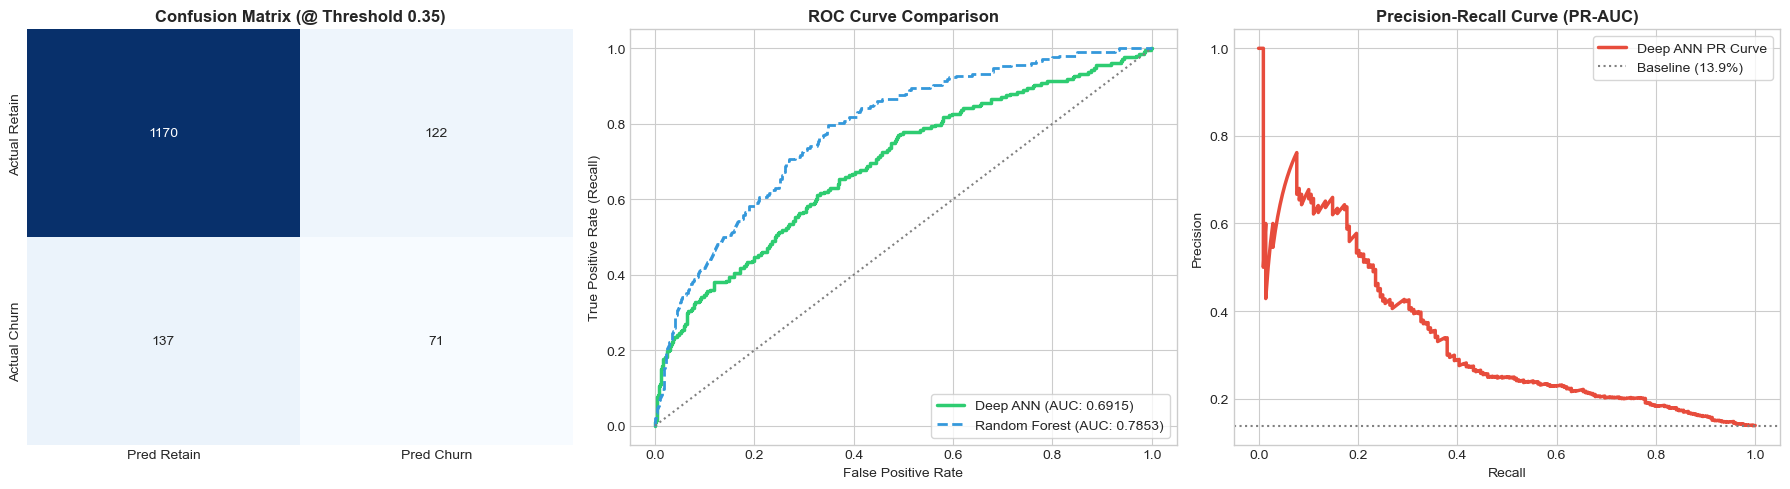

CLASSIFICATION REPORT (@ THRESHOLD 0.35)
              precision    recall  f1-score   support

    Retained       0.90      0.91      0.90      1292
     Churned       0.37      0.34      0.35       208

    accuracy                           0.83      1500
   macro avg       0.63      0.62      0.63      1500
weighted avg       0.82      0.83      0.82      1500



In [6]:
# Diagnostic Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix
y_pred_35 = (y_prob_ann >= 0.35).astype(int)
cm = confusion_matrix(y_test, y_pred_35)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Pred Retain', 'Pred Churn'], yticklabels=['Actual Retain', 'Actual Churn'])
axes[0].set_title('Confusion Matrix (@ Threshold 0.35)', fontweight='bold')

# 2. ROC Curve
fpr_ann, tpr_ann, _ = roc_curve(y_test, y_prob_ann)
fpr_rf, tpr_rf, _   = roc_curve(y_test, y_prob_rf)
axes[1].plot(fpr_ann, tpr_ann, color='#2ecc71', linewidth=2.5, label=f'Deep ANN (AUC: {roc_auc_score(y_test, y_prob_ann):.4f})')
axes[1].plot(fpr_rf, tpr_rf, color='#3498db', linestyle='--', linewidth=2, label=f'Random Forest (AUC: {roc_auc_score(y_test, y_prob_rf):.4f})')
axes[1].plot([0, 1], [0, 1], 'gray', linestyle=':')
axes[1].set_title('ROC Curve Comparison', fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].legend(loc='lower right', frameon=True)

# 3. Precision-Recall Curve
prec, rec, _ = precision_recall_curve(y_test, y_prob_ann)
axes[2].plot(rec, prec, color='#e74c3c', linewidth=2.5, label='Deep ANN PR Curve')
axes[2].axhline(y_test.mean(), color='gray', linestyle=':', label=f'Baseline ({y_test.mean():.1%})')
axes[2].set_title('Precision-Recall Curve (PR-AUC)', fontweight='bold')
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].legend(frameon=True)

plt.tight_layout()
plt.show()

print("=" * 65)
print("CLASSIFICATION REPORT (@ THRESHOLD 0.35)")
print("=" * 65)
print(classification_report(y_test, y_pred_35, target_names=['Retained', 'Churned']))


## 5. Real-Time Production Inference Pipeline

In [7]:
def predict_customer_churn(customer_dict, model, scaler, cols, threshold=0.35):
    input_df = pd.DataFrame([customer_dict])
    input_df['Gender'] = input_df['Gender'].map({'Female': 0, 'Male': 1})
    input_df = pd.get_dummies(input_df, columns=['Geography'], drop_first=False, dtype=int)

    for c in cols:
        if c not in input_df.columns:
            input_df[c] = 0
    input_df = input_df[cols]

    scaled = scaler.transform(input_df)
    if HAS_TF:
        prob = float(model.predict(scaled, verbose=0)[0][0])
    else:
        prob = float(model.predict_proba(scaled)[0][1])

    is_churn = prob >= threshold
    if prob >= 0.70:
        tier, action = "CRITICAL RISK", "Dedicated Account Executive + Fee Waiver & Loan Discount"
    elif prob >= 0.35:
        tier, action = "ELEVATED RISK", "Personalized Cash-Back Promotion & Credit Card Upgrade"
    else:
        tier, action = "LOW RISK", "Maintain Standard Service & Cross-Sell Investment Products"

    return {
        'Customer': customer_dict.get('Surname', 'Valued Client'),
        'Churn_Probability': f"{prob:.2%}",
        'Prediction': "CHURN AT RISK" if is_churn else "RETAINED",
        'Risk_Tier': tier,
        'Recommended_Action': action
    }

sample_client = {
    'Surname': 'Schneider',
    'CreditScore': 615,
    'Geography': 'Germany',
    'Gender': 'Female',
    'Age': 49,
    'Tenure': 2,
    'Balance': 135000.0,
    'NumOfProducts': 3,
    'HasCrCard': 1,
    'IsActiveMember': 0,
    'EstimatedSalary': 78000.0
}

print("=" * 70)
print("PRODUCTION INFERENCE RESULT")
print("=" * 70)
for k, v in predict_customer_churn(sample_client, ann_model, scaler, feature_names).items():
    print(f"{k:22}: {v}")


PRODUCTION INFERENCE RESULT
Customer              : Schneider
Churn_Probability     : 96.10%
Prediction            : CHURN AT RISK
Risk_Tier             : CRITICAL RISK
Recommended_Action    : Dedicated Account Executive + Fee Waiver & Loan Discount
